In [17]:
%pip install numpy gdown matplotlib pandas opencv-python ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.6/876.6 kB 27.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 34.8 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 31.2 MB/s  0:00:15m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 31.1 MB/s  0:00:16m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 33.5 MB/s  0:00:05m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 30.3 MB/s  0:00:07m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 30.8 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 20.5 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 26.2 MB/s  0:00:14m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 38.1 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90

In [18]:
import gdown
import numpy as np
from pathlib import Path
import zipfile
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import pandas as pd
from collections import Counter
import os
import cv2
from ultralytics import YOLO

In [3]:
file_id = "1JbFzlo4GTYtSu8oPsSFHv9FFzg-fGDgB"
zip_path = "data.zip"

url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url,zip_path,quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1JbFzlo4GTYtSu8oPsSFHv9FFzg-fGDgB
From (redirected): https://drive.google.com/uc?id=1JbFzlo4GTYtSu8oPsSFHv9FFzg-fGDgB&confirm=t&uuid=01e7ee89-f6c5-4e54-9a42-4efff13f7737
To: /data.zip
100%|██████████| 139M/139M [00:03<00:00, 38.4MB/s] 


'data.zip'

In [4]:
data_dir = Path(zip_path)

if data_dir.is_file() and data_dir.suffix.lower() == ".zip":
        extract_dir = data_dir.with_suffix("")

with zipfile.ZipFile(data_dir,"r") as zip_file:
            zip_file.extractall(extract_dir)
            
            data_dir = extract_dir

In [5]:
data_dir = Path(data_dir)
data_dir = data_dir


In [6]:
print("Dataset path:", data_dir.resolve())

Dataset path: /data


In [7]:
train_path = data_dir / "Train"
val_path = data_dir / "Val"
classes = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

In [11]:
def load_data(data_path):
    images = []
    labels = []
    for class_label in classes:
        class_path = os.path.join(data_path, class_label, 'images')
        label_path = os.path.join(data_path, class_label, 'labels')
        for img_file in os.listdir(class_path):
            img = cv2.imread(os.path.join(class_path, img_file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            label_file = img_file.replace('.jpg', '.txt')
            label_file_path = os.path.join(label_path, label_file)
            if os.path.exists(label_file_path):
                with open(label_file_path, 'r') as file:
                    label_data = file.readline().strip().split()
                    if len(label_data) > 0:
                        images.append(img)
                        labels.append(label_data)
                    else:
                        print(f"Label file {label_file_path} is empty, skipping this image.")
            else:
                print(f"Label file {label_file_path} not found, skipping this image.")
    return images, labels   
            

In [12]:
train_images , train_labels = load_data(train_path)
val_images , val_labels_= load_data(val_path)


Label file data/Val/Glioma/labels/gg (342).txt is empty, skipping this image.
Label file data/Val/No Tumor/labels/image(55).txt not found, skipping this image.
Label file data/Val/No Tumor/labels/image(61).txt not found, skipping this image.


In [13]:
print(len(train_images))
print(len(train_labels))
print(len(val_images))
print(len(val_labels_))

4737
4737
509
509


In [14]:
def preprocess_images(images):
    prorocesed_images = []
    
    for img in images:
        img_resized = cv2.resize(img,(224,224))
        prorocesed_images.append(img_resized)
    return np.array(prorocesed_images)    

In [15]:
train_images = preprocess_images(train_images)
val_images = preprocess_images(val_images)

In [ ]:
model = YOLO("yolo26s.pt")

In [ ]:
model.train(data='/config/data.yaml', epochs=35, imgsz=640,batch=-1,patience=6)

In [ ]:
metrics = model.val(split='val')
metrics_df = pd.DataFrame.from_dict(metrics.results_dict, orient='index', columns=['Metrics Values'])

metrics_df.round(3)

In [43]:
print(list(data_dir.iterdir()))

[PosixPath('data/Train'), PosixPath('data/Val')]


In [44]:
for path in data_dir.rglob("*"):
    if path.is_dir() and path.name in ['images','labels']:
        print(path)

data/Train/Glioma/images
data/Train/Glioma/labels
data/Train/Meningioma/images
data/Train/Meningioma/labels
data/Train/No Tumor/images
data/Train/No Tumor/labels
data/Train/Pituitary/images
data/Train/Pituitary/labels
data/Val/Glioma/images
data/Val/Glioma/labels
data/Val/Meningioma/images
data/Val/Meningioma/labels
data/Val/No Tumor/images
data/Val/No Tumor/labels
data/Val/Pituitary/images
data/Val/Pituitary/labels


Number of images: 5249
Examples: [PosixPath('data/Train/Glioma/images/Te-glTr_0000.jpg'), PosixPath('data/Train/Glioma/images/Te-glTr_0005.jpg'), PosixPath('data/Train/Glioma/images/Te-glTr_0007.jpg'), PosixPath('data/Train/Glioma/images/Te-gl_0014.jpg'), PosixPath('data/Train/Glioma/images/Te-gl_0015.jpg')]


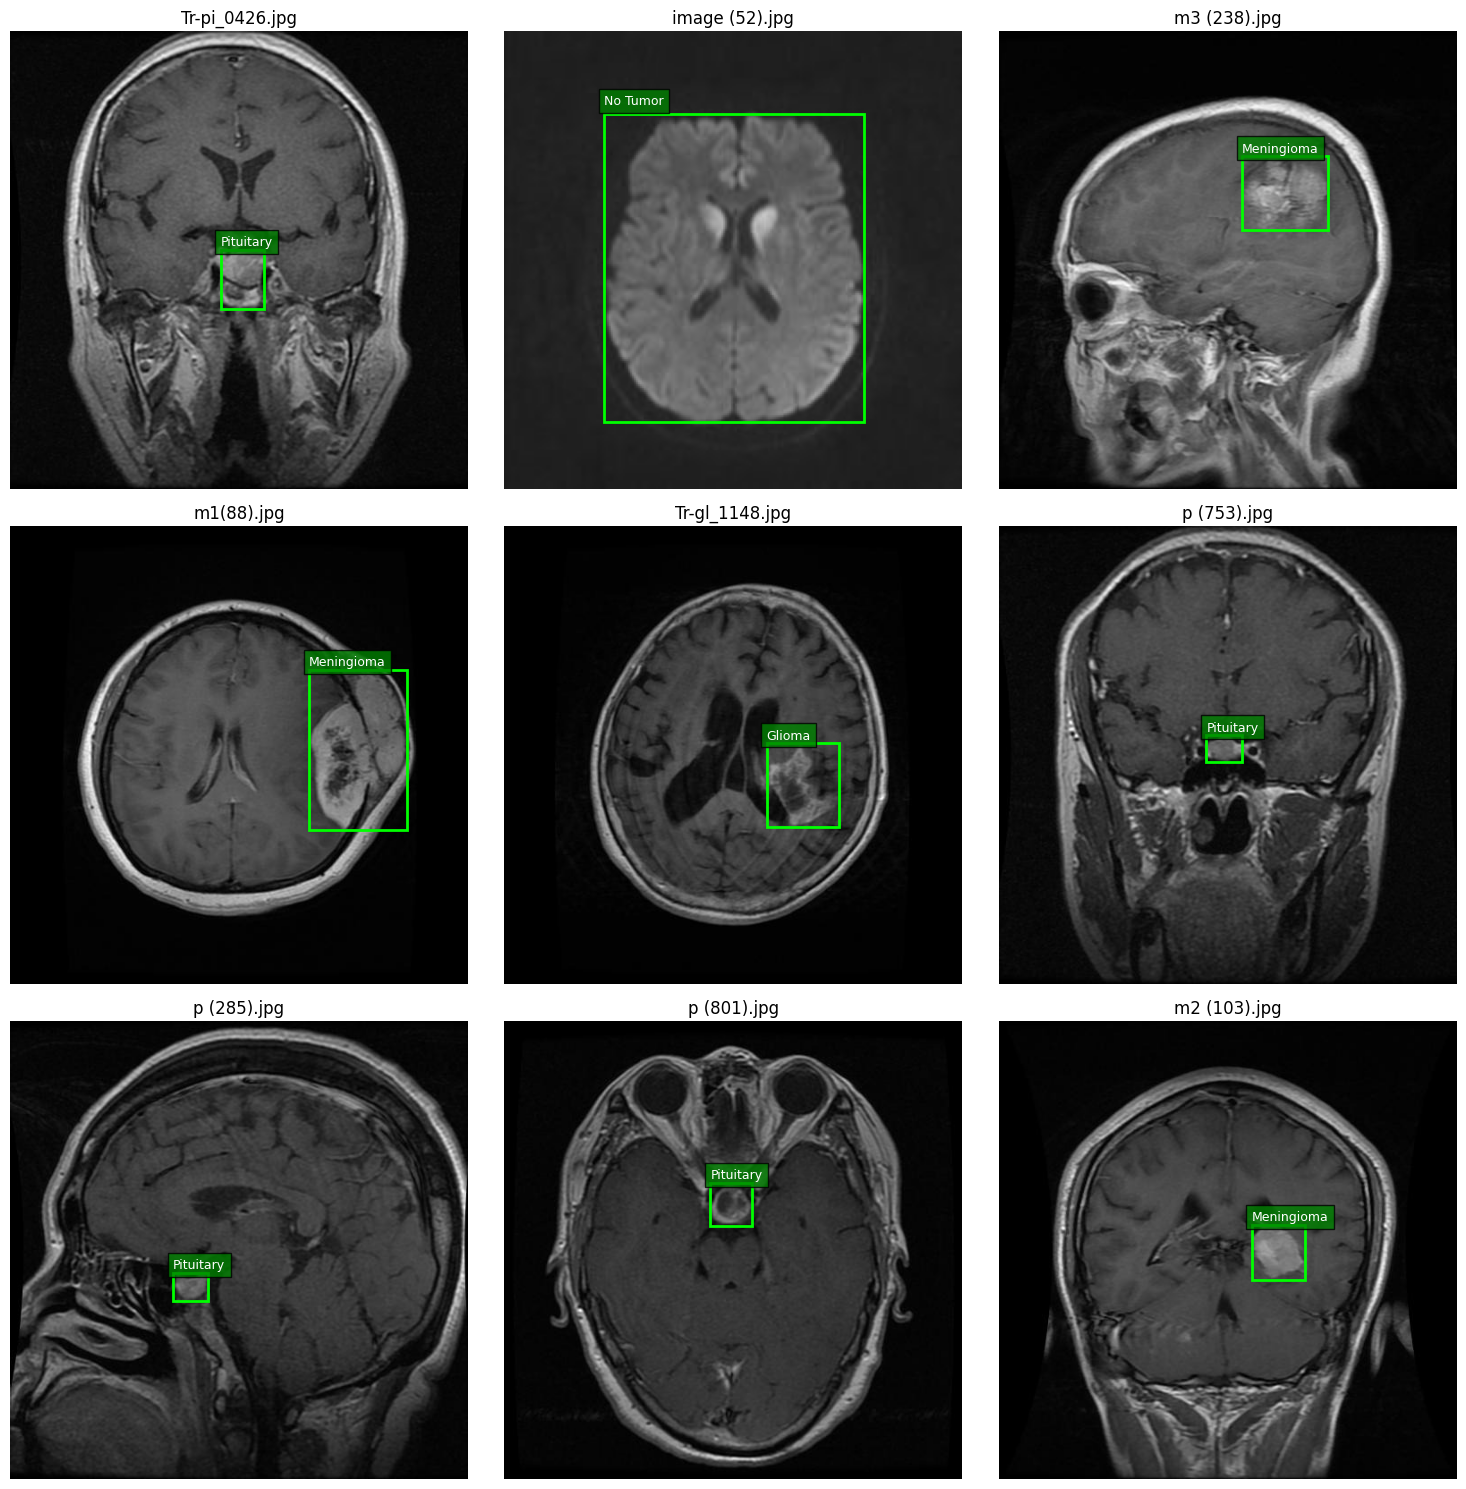

,class_id,class_name,images,bounding_boxes
0,0,Glioma,1287,1502
1,1,Meningioma,1582,1624
2,2,No Tumor,809,809
3,3,Pituitary,1825,1936


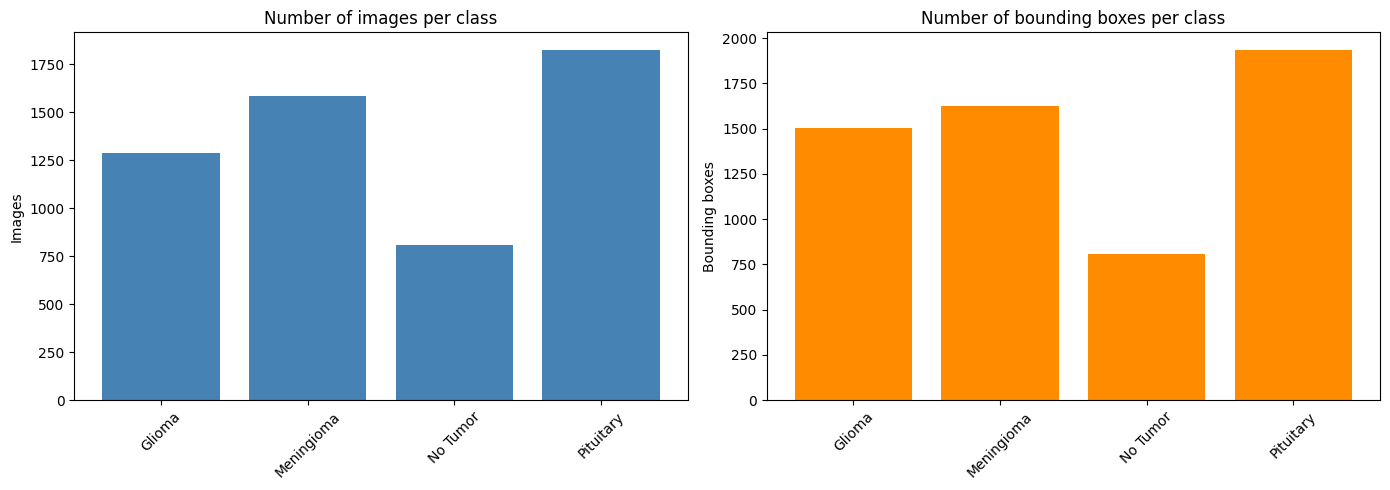


images:
Most represented class: Pituitary
Imbalance ratio: 2.26
No strong imbalance detected using the 3:1 threshold.

bounding_boxes:
Most represented class: Pituitary
Imbalance ratio: 2.39
No strong imbalance detected using the 3:1 threshold.


In [53]:
def read_yolo_labels(label_path):
    annotations = []

    if not label_path.exists():
        return annotations

    with open(label_path, "r") as file:
        for line in file:
            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id, xc, yc, w, h = values

            annotations.append({
                "class_id": int(class_id),
                "x_center": float(xc),
                "y_center": float(yc),
                "width": float(w),
                "height": float(h)
            })

    return annotations

def yolo_to_pixels(annotation, image_width, image_height):
    xc = annotation["x_center"] * image_width
    yc = annotation["y_center"] * image_height

    w = annotation["width"] * image_width
    h = annotation["height"] * image_height

    x1 = xc - w / 2
    y1 = yc - h / 2
    x2 = xc + w / 2
    y2 = yc + h / 2

    return x1, y1, x2, y2

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = [
    p for p in data_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    and p.parent.name == "images"
]

print("Number of images:", len(image_paths))
print("Examples:", image_paths[:5])


def get_label_path(image_path):
    return (
        image_path.parent.parent
        / "labels"
        / (image_path.stem + ".txt")
    )

class_names = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary"
}


valid_images = [
    p for p in image_paths
    if get_label_path(p).exists()
]

if not valid_images:
    print("No matching image-label pairs found. Check the folder structure.")
else:
    samples = random.sample(valid_images, min(9, len(valid_images)))

    fig, axes = plt.subplots(3, 3, figsize=(15, 15))
    axes = axes.flatten()

    for ax, image_path in zip(axes, samples):
        image = Image.open(image_path).convert("RGB")
        W, H = image.size

        ax.imshow(image)

        annotations = read_yolo_labels(get_label_path(image_path))

        for ann in annotations:
            x1, y1, x2, y2 = yolo_to_pixels(ann, W, H)

            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=2,
                edgecolor="lime",
                facecolor="none"
            )

            ax.add_patch(rect)

            class_name = class_names.get(
                ann["class_id"],
                f"Class {ann['class_id']}"
            )

            ax.text(
                x1,
                max(0, y1 - 5),
                class_name,
                color="white",
                fontsize=9,
                bbox=dict(facecolor="green", alpha=0.8)
            )

        ax.set_title(image_path.name)
        ax.axis("off")

    for ax in axes[len(samples):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    
    
    image_counts = Counter()
box_counts = Counter()

for image_path in image_paths:
    label_path = get_label_path(image_path)
    annotations = read_yolo_labels(label_path)

    classes_in_image = set()

    for ann in annotations:
        class_id = ann["class_id"]

        box_counts[class_id] += 1
        classes_in_image.add(class_id)

    for class_id in classes_in_image:
        image_counts[class_id] += 1

all_class_ids = sorted(set(image_counts) | set(box_counts))

distribution = pd.DataFrame([
    {
        "class_id": cid,
        "class_name": class_names.get(cid, f"Class {cid}"),
        "images": image_counts[cid],
        "bounding_boxes": box_counts[cid]
    }
    for cid in all_class_ids
])

display(distribution)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    distribution["class_name"],
    distribution["images"],
    color="steelblue"
)
axes[0].set_title("Number of images per class")
axes[0].set_ylabel("Images")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(
    distribution["class_name"],
    distribution["bounding_boxes"],
    color="darkorange"
)
axes[1].set_title("Number of bounding boxes per class")
axes[1].set_ylabel("Bounding boxes")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()



for column in ["images", "bounding_boxes"]:
    counts = distribution[column]

    if len(counts) == 0 or counts.max() == 0:
        print(f"No data available for {column}.")
        continue

    imbalance_ratio = counts.max() / counts[counts > 0].min()

    print(f"\n{column}:")
    print("Most represented class:", distribution.loc[counts.idxmax(), "class_name"])
    print("Imbalance ratio:", round(imbalance_ratio, 2))

    if imbalance_ratio >= 3:
        print("Possible class imbalance detected.")
    else:
        print("No strong imbalance detected using the 3:1 threshold.")